#Optimisation quantitative de portefeuille.

##Objectif: Développer et comparer plusieurs modèles d'allocation de portefeuille pour optimiser le rendement ajusté au risque, tout en respectant les contraintes de diversification.

##Modèles étudiés:
1. Allocation équipondérée (Equal weight)
2. Allocation inversement proportionelle à la volatilité (Inverse volatility)
3. Minimisation de la variance (Minimum variance)
4. Maximisation du ratio de Sharpe (Maximum Sharpe)
5. Modèle de Black-Litterman

##Contraintes du portefeuille:
1. Capital initial: € 200 000
2. Capital investi: 90%
3. Réserve de liquidités: 10%
4. Nombre minimum de titres: 16
5. Règle de diversification: 5/10/40

##Méthodologie: 

Les modèles seront construits à partir de données financières quotidiennes couvrant les 5 dernières années (une periode commune d'environ 3 ans sera retenue pour comparer équitablement les 5 modèles vu que certains ETF ne disposent pas de 5 années d'historique). Leurs performances seront comparées à l'aide de plusieurs indicateurs : rendement, volatilité, ratio de Sharpe et drawdown maximal.

Les données seront ensuite divisées en deux périodes: une période d'entraînement pour déterminer les poids optimaux du portefeuille et une périod de test hors échantillon pour évaluer les performances des modèles sur des données non utilisées lors de l'optimisation.

In [1]:
import pandas as pd
import numpy as np
import yfinance as yf
import matplotlib.pyplot as plt
from scipy.optimize import minimize

In [2]:
#parametres et contraintes du portefeuille

initial_capital=200000
investment_fraction= 0.90
cash_fraction= 0.10

min_securities= 16
max_weight= 0.10
large_weight_threshold= 0.05
large_weight_limit= 0.40

invested_capital= initial_capital * investment_fraction
cash_reserve= initial_capital * cash_fraction

print("Capital_initial: €", initial_capital)
print("Capital à investir: €", invested_capital)
print("Réserve de liquidités: €", cash_reserve)

Capital_initial: € 200000
Capital a investir: € 180000.0
Réserve de liquidités: € 20000.0


In [13]:
#Importer les actifs sélectionnés: Les poids du portefeuille seront déterminés indépendamment à partir de nos modèles quantitatifs.

%pip install openpyxl

assets = pd.read_excel(
    "Synapse Capital Market Analysis (1).xlsx",
    sheet_name="Main",
    usecols=["Nom", "Ticker", "Market [Bourse]","Interest"]
)

assets = assets[
    assets["Interest"].fillna("").str.startswith("Interested")
    & (assets["Ticker"] != "3AAP")
].copy()

assets.index = range(1, len(assets) + 1)

print("Nombre d'actifs sélectionnés :", len(assets))

assets

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.
Nombre d'actifs sélectionnés : 22


,Nom,Ticker,Market [Bourse],Interest
1,iS Agri bus Acc,ISAE,Amsterdam,Interested
2,SPDR MSCI W C STAP,WCOS,Amsterdam,Interested
3,LEONARDO,LDO,Milan,Interested
4,SPIE,SPIE,Paris,Interested
5,MSCI Wld Hlth US A,WHCA,Amsterdam,Interested
6,THALES,HO,Paris,Interested
7,ADYEN,ADYEN,Amsterdam,Interested
8,ASML HOLDING,ASML,Amsterdam,Interested
9,TECHNIP ENERGIES,TE,Paris,Interested
10,VANETFMVNUCLXPAR,NUCL,Paris,Interested


In [16]:
#Harmonisation des tickers

exchange_suffix = {
    "Paris": ".PA",
    "Amsterdam": ".AS",
    "Milan": ".MI",
    "Dublin": ".IR"
}

assets["YahooTicker"] = (
    assets["Ticker"].str.strip()
    + assets["Market [Bourse]"].str.strip().map(exchange_suffix)
)

print("Nombre d'actifs :", len(assets))
print("Tickers manquants :", assets["YahooTicker"].isna().sum())

assets[["Nom", "Ticker", "YahooTicker", "Market [Bourse]"]]

Nombre d'actifs : 22
Tickers manquants : 0


,Nom,Ticker,YahooTicker,Market [Bourse]
1,iS Agri bus Acc,ISAE,ISAE.AS,Amsterdam
2,SPDR MSCI W C STAP,WCOS,WCOS.AS,Amsterdam
3,LEONARDO,LDO,LDO.MI,Milan
4,SPIE,SPIE,SPIE.PA,Paris
5,MSCI Wld Hlth US A,WHCA,WHCA.AS,Amsterdam
6,THALES,HO,HO.PA,Paris
7,ADYEN,ADYEN,ADYEN.AS,Amsterdam
8,ASML HOLDING,ASML,ASML.AS,Amsterdam
9,TECHNIP ENERGIES,TE,TE.PA,Paris
10,VANETFMVNUCLXPAR,NUCL,NUCL.PA,Paris


In [15]:
#donnees historique
tickers = assets["YahooTicker"].tolist()
prices_all = yf.download(
    tickers,
    period="5y",
    interval="1d",
    auto_adjust=True,
    progress=False
)["Close"]
print("Nombre d'actifs demandés :", len(tickers))
print("Nombre d'actifs téléchargés :", prices_all.shape[1])
print("Nombre de dates :", len(prices_all))
print("Première date :", prices_all.index.min())
print("Dernière date :", prices_all.index.max())

prices_all.head()

Nombre d'actifs demandés : 22
Nombre d'actifs téléchargés : 22
Nombre de dates : 1281
Première date : 2021-10-26 00:00:00
Dernière date : 2026-10-26 00:00:00


Ticker,ADYEN.AS,AM.PA,ASM.AS,ASML.AS,BATT.AS,CRL.MI,ERA.PA,FOHW.PA,GL9.IR,HO.PA,...,LDO.MI,LR.PA,NEX.PA,NUCL.PA,PRY.MI,SPIE.PA,SU.PA,TE.PA,WCOS.AS,WHCA.AS
Date,,,,,,,,,,,,,,,,,,,,,
2021-10-26,2721.5,83.241966,342.702942,647.650696,16.450300,23.434021,68.144913,NaN,12.277943,73.339363,...,6.164671,85.153137,76.397324,NaN,30.365303,18.419727,130.391144,11.770741,37.514999,NaN
2021-10-27,2667.0,82.919502,363.855011,661.843811,16.301600,23.480701,65.435364,NaN,12.207685,73.014778,...,6.106442,85.424896,76.262657,NaN,30.142300,18.507778,133.531357,11.514856,37.435001,NaN
2021-10-28,2630.5,83.380173,373.654877,665.273071,16.196100,23.247295,64.712830,NaN,12.365769,72.600021,...,6.046336,86.312660,76.935966,NaN,30.411758,18.578213,135.923004,11.345712,37.375000,NaN
2021-10-29,2610.5,83.149834,379.767578,667.273499,16.351101,23.340660,65.299904,NaN,12.409682,71.824623,...,5.952419,85.370544,77.788818,NaN,30.383884,18.490166,135.923004,11.558226,37.759998,NaN
2021-11-01,2564.5,83.610504,385.201172,663.558411,16.585501,23.387341,65.525696,NaN,12.339421,72.059036,...,6.042580,86.566315,78.372353,NaN,30.541843,18.754309,136.050797,11.458475,37.775002,NaN


In [19]:
#clean data to find out which dates to use
data_quality = pd.DataFrame({
    "Première date": prices_all.apply(lambda col: col.first_valid_index()),
    "Dernière date": prices_all.apply(lambda col: col.last_valid_index()),
    "Observations": prices_all.notna().sum(),
    "Valeurs manquantes": prices_all.isna().sum()
})

data_quality = data_quality.sort_values("Première date")

data_quality

,Première date,Dernière date,Observations,Valeurs manquantes
Ticker,,,,
ADYEN.AS,2021-10-26,2026-10-26,1281,0
SU.PA,2021-10-26,2026-10-26,1281,0
NEX.PA,2021-10-26,2026-10-26,1281,0
LR.PA,2021-10-26,2026-10-26,1281,0
LDO.MI,2021-10-26,2026-10-26,1271,10
ITWN.AS,2021-10-26,2026-10-26,1279,2
WCOS.AS,2021-10-26,2026-10-26,1279,2
HO.PA,2021-10-26,2026-10-26,1281,0
GL9.IR,2021-10-26,2026-10-26,1272,9


In [20]:
#Recherche d'historiques complémentaires
alternative_prices = yf.download(
    ["NUCL.MI", "FOHW.MI"],
    period="5y",
    interval="1d",
    auto_adjust=True,
    progress=False
)["Close"]
#Vérification de la première date disponible
print(alternative_prices.apply(lambda col: col.first_valid_index()))

Ticker
FOHW.MI   2023-07-20
NUCL.MI   2023-04-24
dtype: datetime64[ns]


In [21]:
#construction de bases des donnees
prices_model = prices_all.drop(columns=["NUCL.PA", "FOHW.PA"])
prices_model = prices_model.join(alternative_prices)
prices_3y = prices_model.loc["2023-10-26":"2026-10-26"].copy()
print("Nombre d'actifs :", prices_3y.shape[1])
print("Nombre de dates :", prices_3y.shape[0])
print("\nValeurs manquantes par actif :")
print(prices_3y.isna().sum().sort_values(ascending=False))

Nombre d'actifs : 22
Nombre de dates : 765

Valeurs manquantes par actif :
Ticker
WHCA.AS     66
FOHW.MI      8
NUCL.MI      8
LDO.MI       6
CRL.MI       6
PRY.MI       6
GL9.IR       3
WCOS.AS      2
ITWN.AS      2
ISAE.AS      2
BATT.AS      2
ASML.AS      0
ADYEN.AS     0
AM.PA        0
ASM.AS       0
LR.PA        0
ERA.PA       0
HO.PA        0
NEX.PA       0
TE.PA        0
SPIE.PA      0
SU.PA        0
dtype: int64


In [23]:
#nettoyage des donnees et calculer les rendements

prices_clean = prices_3y.ffill(limit=1).dropna(how="any")

print("Dates initiales :", len(prices_3y))
print("Dates conservées :", len(prices_clean))
print("Dates supprimées :", len(prices_3y) - len(prices_clean))
returns = prices_clean.pct_change(fill_method=None).dropna()

#separaration entrainment et test
train_returns = returns.loc[returns.index < "2025-10-26"]
test_returns = returns.loc[returns.index >= "2025-10-26"]

print("\nObservations d'entraînement :", len(train_returns))
print("Observations de test :", len(test_returns))

print("\nPériode d'entraînement :")
print(train_returns.index.min(), "à", train_returns.index.max())

print("\nPériode de test :")
print(test_returns.index.min(), "à", test_returns.index.max())

Dates initiales : 765
Dates conservées : 701
Dates supprimées : 64

Observations d'entraînement : 509
Observations de test : 191

Période d'entraînement :
2023-10-27 00:00:00 à 2025-10-24 00:00:00

Période de test :
2025-10-27 00:00:00 à 2026-10-26 00:00:00


In [25]:
# Téléchargation WHCA.Londres et le taux de change GBP/EUR, BlackRock confirme que WHCA.L et WHCA.AS correspondent au meme ETF
whca_data = yf.download(
    ["WHCA.L", "GBPEUR=X"],
    period="5y",
    interval="1d",
    auto_adjust=True,
    progress=False
)["Close"]

whca_eur = whca_data["WHCA.L"] * whca_data["GBPEUR=X"]
print("Première date :", whca_eur.first_valid_index())
print("Dernière date :", whca_eur.last_valid_index())

print(
    "Valeurs manquantes depuis janvier 2024 :",
    whca_eur.loc["2024-01-15":].isna().sum()
)

Première date : 2021-11-05 00:00:00
Dernière date : 2026-10-26 00:00:00
Valeurs manquantes depuis janvier 2024 : 17


In [26]:
whca_comparison = pd.DataFrame({
    "Amsterdam_EUR": prices_model["WHCA.AS"],
    "London_EUR": whca_eur.reindex(prices_model.index)
}).loc["2024-01-15":"2026-10-26"]

overlap = whca_comparison.dropna()

ratio = overlap["Amsterdam_EUR"] / overlap["London_EUR"]

print("Dates communes :", len(overlap))
print("Ratio médian des prix :", round(ratio.median(), 4))

print("Valeurs manquantes à Amsterdam :",
      whca_comparison["Amsterdam_EUR"].isna().sum())

print("Valeurs manquantes à Londres :",
      whca_comparison["London_EUR"].isna().sum())

print("Dates manquantes sur les deux marchés :",
      whca_comparison.isna().all(axis=1).sum())

Dates communes : 635
Ratio médian des prix : 1.0002
Valeurs manquantes à Amsterdam : 66
Valeurs manquantes à Londres : 10
Dates manquantes sur les deux marchés : 0


In [27]:
london_eur = whca_eur.reindex(prices_model.index).copy()
london_eur.loc[:"2024-01-14"] = np.nan
prices_model["WHCA.AS"] = prices_model["WHCA.AS"].fillna(london_eur)
prices_3y = prices_model.loc["2023-10-26":"2026-10-26"].copy()
print("Valeurs manquantes pour WHCA :",
      prices_3y["WHCA.AS"].isna().sum())

print("\nValeurs manquantes par actif :")
print(prices_3y.isna().sum().sort_values(ascending=False))

Valeurs manquantes pour WHCA : 0

Valeurs manquantes par actif :
Ticker
FOHW.MI     8
NUCL.MI     8
PRY.MI      6
LDO.MI      6
CRL.MI      6
GL9.IR      3
BATT.AS     2
WCOS.AS     2
ITWN.AS     2
ISAE.AS     2
ASM.AS      0
ASML.AS     0
ADYEN.AS    0
AM.PA       0
NEX.PA      0
LR.PA       0
ERA.PA      0
HO.PA       0
TE.PA       0
SU.PA       0
SPIE.PA     0
WHCA.AS     0
dtype: int64


In [29]:
# Compléter les valeurs manquantes isolées
prices_clean = prices_3y.ffill(limit=1).dropna(how="any")

#rendements quotidiens
returns = prices_clean.pct_change(fill_method=None).dropna()

# Séparation les données d'entraînement et de test
train_returns = returns.loc[returns.index < "2025-10-26"].copy()
test_returns = returns.loc[returns.index >= "2025-10-26"].copy()

print("Nombre d'actifs :", len(returns.columns))
print("Dates initiales :", len(prices_3y))
print("Dates conservées :", len(prices_clean))
print("Dates supprimées :", len(prices_3y) - len(prices_clean))
print("\nObservations d'entraînement :", len(train_returns))
print("Observations de test :", len(test_returns))
print("\nPériode d'entraînement :")
print(train_returns.index.min(), "à", train_returns.index.max())
print("\nPériode de test :")
print(test_returns.index.min(), "à", test_returns.index.max())


Nombre d'actifs : 22
Dates initiales : 765
Dates conservées : 765
Dates supprimées : 0

Observations d'entraînement : 509
Observations de test : 255

Période d'entraînement :
2023-10-27 00:00:00 à 2025-10-24 00:00:00

Période de test :
2025-10-27 00:00:00 à 2026-10-26 00:00:00


Modèle 1: Portefeuille équipondéré
Le capital investi est réparti de manière égale entre les 22 actifs sélectionnés. Ce modèle ne repose sur aucune estimation des rendements futurs et servira de référence pour comparer les autres stratégies d'allocation.

In [30]:
n_assets = train_returns.shape[1]
weights_equal = pd.Series(
    investment_fraction / n_assets,
    index=train_returns.columns
)
allocation_equal = pd.DataFrame({
    "Poids (%)": weights_equal * 100,
    "Montant (€)": weights_equal * initial_capital
})

display(allocation_equal.round(2))

# Vérification des contraintes
print("Nombre d'actifs :", (weights_equal > 0).sum())
print("Poids maximal :", round(weights_equal.max() * 100, 2), "%")
print("Total investi :", round(weights_equal.sum() * 100, 2), "%")
print("Liquidités :", round((1 - weights_equal.sum()) * 100, 2), "%")

,Poids (%),Montant (€)
Ticker,,
ADYEN.AS,4.09,8181.82
AM.PA,4.09,8181.82
ASM.AS,4.09,8181.82
ASML.AS,4.09,8181.82
BATT.AS,4.09,8181.82
CRL.MI,4.09,8181.82
ERA.PA,4.09,8181.82
GL9.IR,4.09,8181.82
HO.PA,4.09,8181.82


Nombre d'actifs : 22
Poids maximal : 4.09 %
Total investi : 90.0 %
Liquidités : 10.0 %


Modèle 5 : Black–Litterman
Le modèle Black–Litterman combine une estimation initiale des rendements avec nos propres anticipations (views), en tenant compte du niveau de confiance accordé à celles-ci.

Contrairement au code du ZIP, qui combine Black–Litterman avec le modèle HRP et utilise des convictions prédéfinies, nous allons étudier Black–Litterman séparément pour pouvoir le comparer équitablement aux quatre autres modèles.
Nous utiliserons une allocation équipondérée comme point de départ et construirons nos propres anticipations uniquement à partir des données d'entraînement. Le portefeuille final devra également respecter nos contraintes : 90 % investis, 10 % de liquidités et la règle 5/10/40.

In [38]:
benchmark_weights = weights_equal / investment_fraction

# Paramètres Black-Litterman
risk_aversion_bl = 2.5
tau_bl = 0.05

pi_bl = risk_aversion_bl * (cov_train @ benchmark_weights)
print("Somme des poids de référence :",
      round(benchmark_weights.sum() * 100, 2), "%")

print("\nRendements implicites annualisés :")

display(
    (pi_bl * 100)
    .sort_values(ascending=False)
    .to_frame("Rendement implicite (%)")
    .round(2)
)

Somme des poids de référence : 100.0 %

Rendements implicites annualisés :


,Rendement implicite (%)
Ticker,
ASM.AS,10.83
ASML.AS,10.58
ADYEN.AS,9.92
PRY.MI,9.68
SU.PA,8.99
ERA.PA,8.46
NUCL.MI,8.28
NEX.PA,8.08
CRL.MI,7.69


Construction des anticipations:
Les anticipations seront construites à partir d'un signal de momentum calculé sur les six derniers mois de la période d'entraînement. Les trois actifs présentant le momentum le plus élevé et les trois actifs présentant le momentum le plus faible seront identifiés afin de formuler une anticipation relative.
Les données de test ne seront pas utilisées pour sélectionner ces actifs.

In [40]:
# Calculer le momentum sur les 126 derniers jours de Bourse pour identifier le top 3 et 3 derniers
momentum_6m = (1 + train_returns.tail(126)).prod() - 1
top_3 = momentum_6m.nlargest(3)
bottom_3 = momentum_6m.nsmallest(3)

print("Les trois meilleurs momentum :")
display((top_3 * 100).round(2))

print("\nLes trois moins bons momentum :")
display((bottom_3 * 100).round(2))

Les trois meilleurs momentum :


Ticker
NUCL.MI    98.45
PRY.MI     87.65
BATT.AS    58.00
dtype: float64


Les trois moins bons momentum :


Ticker
AM.PA     -10.11
WCOS.AS    -1.91
WHCA.AS     3.53
dtype: float64

Anticipation relative fondée sur le momentum
Les trois actifs ayant le meilleur momentum sont comparés aux trois actifs ayant le momentum le plus faible. Nous formulons l'hypothèse que le premier groupe pourrait surperformer le second de 2 points de pourcentage supplémentaires par an par rapport à l'écart de rendement implicite.
Un niveau de confiance initial de 50 % est retenu. Ces hypothèses feront ensuite l'objet d'une analyse de sensibilité.

In [41]:
view_weights = pd.Series(0.0, index=train_returns.columns)
view_weights.loc[top_3.index] = 1 / 3
view_weights.loc[bottom_3.index] = -1 / 3
P_bl = view_weights.to_numpy().reshape(1, -1)
prior_spread = float(view_weights @ pi_bl)
additional_premium = 0.02
Q_bl = np.array([prior_spread + additional_premium])
confidence_bl = 0.50

print("Écart implicite initial :",
      round(prior_spread * 100, 2), "%")

print("Écart attendu selon notre anticipation :",
      round(Q_bl[0] * 100, 2), "%")

print("Niveau de confiance :", confidence_bl * 100, "%")

Écart implicite initial : 5.58 %
Écart attendu selon notre anticipation : 7.58 %
Niveau de confiance : 50.0 %


In [42]:
sigma_bl = cov_train.to_numpy()
tau_sigma = tau_bl * sigma_bl
view_variance = np.diag(P_bl @ tau_sigma @ P_bl.T)

omega_bl = np.diag(
    view_variance * (1 - confidence_bl) / confidence_bl
)
view_difference = Q_bl - P_bl @ pi_bl.to_numpy()

middle_matrix = P_bl @ tau_sigma @ P_bl.T + omega_bl
adjustment = (
    tau_sigma @ P_bl.T
    @ np.linalg.solve(middle_matrix, view_difference)
)

mu_bl = pd.Series(
    pi_bl.to_numpy() + adjustment,
    index=train_returns.columns
)
posterior_uncertainty = (
    tau_sigma
    - tau_sigma @ P_bl.T
    @ np.linalg.solve(middle_matrix, P_bl @ tau_sigma)
)
cov_bl = sigma_bl + posterior_uncertainty
cov_bl = (cov_bl + cov_bl.T) / 2
bl_comparison = pd.DataFrame({
    "Initial (%)": pi_bl * 100,
    "Black-Litterman (%)": mu_bl * 100,
    "Ajustement (points)": (mu_bl - pi_bl) * 100
})

display(
    bl_comparison
    .sort_values("Ajustement (points)", ascending=False)
    .round(2)
)
adjusted_spread = (P_bl @ mu_bl.to_numpy()).item()

print("Écart initial :", round(prior_spread * 100, 2), "%")
print("Écart ajusté :", round(adjusted_spread * 100, 2), "%")
print("Anticipation :", round(Q_bl[0] * 100, 2), "%")

,Initial (%),Black-Litterman (%),Ajustement (points)
Ticker,,,
NUCL.MI,8.28,9.33,1.05
PRY.MI,9.68,10.63,0.94
ASM.AS,10.83,11.57,0.74
SU.PA,8.99,9.70,0.71
ASML.AS,10.58,11.28,0.70
BATT.AS,6.97,7.58,0.61
ADYEN.AS,9.92,10.50,0.58
NEX.PA,8.08,8.64,0.56
LR.PA,7.00,7.55,0.55


Écart initial : 5.58 %
Écart ajusté : 6.58 %
Anticipation : 7.58 %


In [43]:
#optimisation du portefeuille Black-Litterman
def negative_utility_bl(weights):
    expected_return = weights @ mu_bl.to_numpy()
    variance = weights @ cov_bl @ weights
    utility = (
        expected_return
        - (risk_aversion_bl / 2) * variance
    )

    return -utility
result_bl = minimize(
    negative_utility_bl,
    x0=weights_equal.to_numpy(),
    method="SLSQP",
    bounds=bounds,
    constraints=constraints,
    options={"ftol": 1e-12, "maxiter": 2000}
)

print("Optimisation réussie :", result_bl.success)
print("Message :", result_bl.message)

if result_bl.success:

    weights_bl = pd.Series(
        result_bl.x,
        index=train_returns.columns
    )

    print("\nNombre d'actifs :",
          (weights_bl > 1e-6).sum())

    print("Total investi :",
          round(weights_bl.sum() * 100, 2), "%")

    print("\nPoids optimisés :")

    display(
        (weights_bl * 100)
        .sort_values(ascending=False)
        .to_frame("Poids (%)")
        .round(2)
    )

Optimisation réussie : True
Message : Optimization terminated successfully

Nombre d'actifs : 21
Total investi : 90.0 %

Poids optimisés :


,Poids (%)
Ticker,
BATT.AS,5.00
SU.PA,5.00
ITWN.AS,5.00
LDO.MI,5.00
LR.PA,5.00
ISAE.AS,5.00
PRY.MI,5.00
NUCL.MI,5.00
NEX.PA,4.87


Comparaison des cinq modèles
Les cinq stratégies sont évaluées à partir des mêmes périodes d'entraînement et de test, en utilisant les mêmes indicateurs de performance.

L'objectif est d'identifier les modèles offrant le meilleur compromis entre rendement et risque, tout en vérifiant si leurs performances restent satisfaisantes hors échantillon.

In [44]:
# Évaluer le portefeuille Black-Litterman
results_bl = pd.DataFrame({
    "Entraînement": portfolio_metrics(weights_bl, train_returns),
    "Hors échantillon": portfolio_metrics(weights_bl, test_returns)
}).T
comparison = pd.concat({
    "Équipondéré": results_equal,
    "Variance minimale": results_minvar,
    "Sharpe maximal": results_sharpe,
    "Risk Parity": results_rp,
    "Black-Litterman": results_bl
}, names=["Modèle", "Période"])
print("Comparaison complète :")
display(comparison.round(2))

# Comparer uniquement les performances hors échantillon
test_comparison = comparison.xs(
    "Hors échantillon",
    level="Période"
)
print("\nClassement hors échantillon selon le Sharpe :")
display(
    test_comparison
    .sort_values("Ratio de Sharpe", ascending=False)
    .round(2)
)

Comparaison complète :


Rendement annualisé (%)  Volatilité (%)  \
Modèle            Période                                                     
Équipondéré       Entraînement                        28.96           14.45   
                  Hors échantillon                     6.70           15.68   
Variance minimale Entraînement                        26.53           12.95   
                  Hors échantillon                     4.61           13.67   
Sharpe maximal    Entraînement                        31.09           13.46   
                  Hors échantillon                     4.97           14.01   
Risk Parity       Entraînement                        26.89           13.27   
                  Hors échantillon                     7.34           14.04   
Black-Litterman   Entraînement                        32.25           15.95   
                  Hors échantillon                     5.54           17.91   

                                    Ratio de Sharpe  Drawdown maximal (%)  
Modèle            Période                                                  
Équipondéré       Entraînement                 1.83                -15.58  
                  Hors échantillon             0.49                -10.28  
Variance minimale Entraînement                 1.88                -14.17  
                  Hors échantillon             0.40                 -8.77  
Sharpe maximal    Entraînement                 2.08                -14.48  
                  Hors échantillon             0.42                 -9.04  
Risk Parity       Entraînement                 1.86                -14.47  
                  Hors échantillon             0.57                 -8.76  
Black-Litterman   Entraînement                 1.83                -17.37  
                  Hors échantillon             0.39                -13.23


Classement hors échantillon selon le Sharpe :


,Rendement annualisé (%),Volatilité (%),Ratio de Sharpe,Drawdown maximal (%)
Modèle,,,,
Risk Parity,7.34,14.04,0.57,-8.76
Équipondéré,6.70,15.68,0.49,-10.28
Sharpe maximal,4.97,14.01,0.42,-9.04
Variance minimale,4.61,13.67,0.40,-8.77
Black-Litterman,5.54,17.91,0.39,-13.23


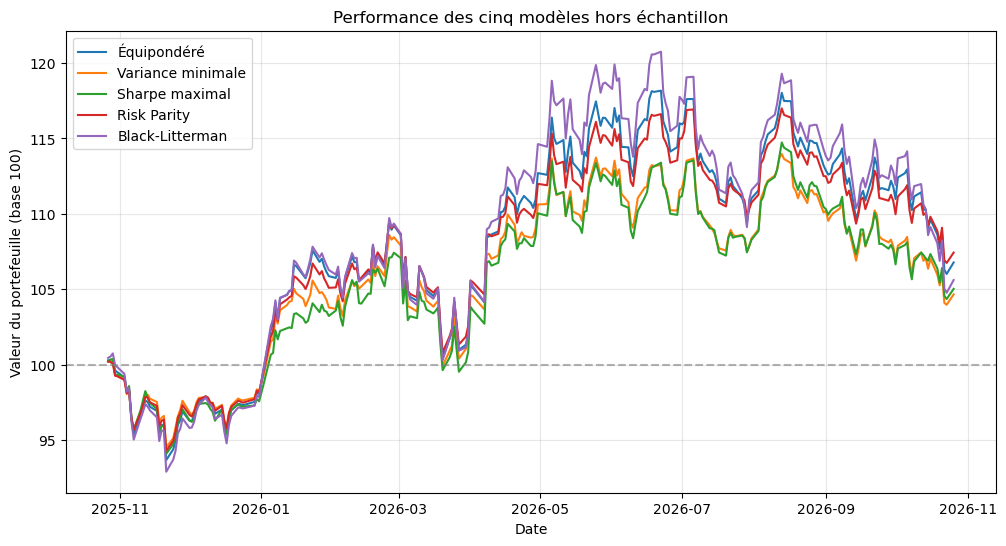

In [45]:
#evolution des portefeuilles echantillon
test_portfolio_returns = pd.DataFrame({
    "Équipondéré": test_returns @ weights_equal,
    "Variance minimale": test_returns @ weights_minvar,
    "Sharpe maximal": test_returns @ weights_sharpe,
    "Risk Parity": test_returns @ weights_rp,
    "Black-Litterman": test_returns @ weights_bl
})
cumulative_performance = (
    1 + test_portfolio_returns
).cumprod() * 100
plt.figure(figsize=(12, 6))

for model in cumulative_performance.columns:
    plt.plot(
        cumulative_performance.index,
        cumulative_performance[model],
        label=model
    )

plt.axhline(100, color="grey", linestyle="--", alpha=0.6)

plt.title("Performance des cinq modèles hors échantillon")
plt.xlabel("Date")
plt.ylabel("Valeur du portefeuille (base 100)")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

Backtest avec rééquilibrage et frais de transaction
Afin d'évaluer les stratégies dans des conditions plus réalistes, un rééquilibrage trimestriel est simulé. Entre deux rééquilibrages, les poids évoluent en fonction des variations des prix.
 La réserve de liquidités est maintenue dans le portefeuille et rétablie à 10 % lors des rééquilibrages.

In [48]:
def backtest_periodic(weights, daily_returns,
                      rebalance_days=63, transaction_cost=0.0):
    asset_weights = weights.reindex(
        daily_returns.columns
    ).to_numpy()

    cash_weight = 1 - asset_weights.sum()
    target_weights = np.append(asset_weights, cash_weight)
    holdings = target_weights.copy()

    daily_portfolio_returns = []

    for day, (_, daily_r) in enumerate(daily_returns.iterrows(), start=1):
        wealth_before = holdings.sum()
        holdings[:-1] *= (1 + daily_r.to_numpy())
        if day % rebalance_days == 0:

            wealth_pre_cost = holdings.sum()
            current_weights = holdings / wealth_pre_cost
            turnover = np.abs(
                target_weights[:-1] - current_weights[:-1]
            ).sum()
            fees = transaction_cost * turnover * wealth_pre_cost
            holdings = (wealth_pre_cost - fees) * target_weights

        wealth_after = holdings.sum()

        daily_portfolio_returns.append(
            wealth_after / wealth_before - 1
        )

    return pd.Series(
        daily_portfolio_returns,
        index=daily_returns.index
    )

In [49]:
model_weights = {
    "Équipondéré": weights_equal,
    "Variance minimale": weights_minvar,
    "Sharpe maximal": weights_sharpe,
    "Risk Parity": weights_rp,
    "Black-Litterman": weights_bl
}
backtests_periodic = {
    name: backtest_periodic(weights, test_returns)
    for name, weights in model_weights.items()
}

periodic_comparison = pd.DataFrame({
    name: portfolio_metrics(
        pd.Series({"Portfolio": 1.0}),
        portfolio_returns.to_frame("Portfolio")
    )
    for name, portfolio_returns in backtests_periodic.items()
}).T

display(
    periodic_comparison
    .sort_values("Ratio de Sharpe", ascending=False)
    .round(2)
)

,Rendement annualisé (%),Volatilité (%),Ratio de Sharpe,Drawdown maximal (%)
Risk Parity,6.25,13.99,0.50,-9.45
Équipondéré,5.57,15.64,0.42,-11.17
Sharpe maximal,3.88,13.96,0.34,-9.52
Black-Litterman,4.49,17.90,0.33,-14.13
Variance minimale,3.56,13.55,0.33,-9.28


Backtesting glissant (walk-forward)
Afin d'évaluer la stabilité des modèles dans différentes conditions de marché, un backtesting glissant est réalisé.

Chaque modèle est optimisé sur une période de 18 mois, puis testé sur les trois mois suivants. La fenêtre d'analyse est ensuite décalée de trois mois et l'opération est répétée.

Cette méthode permet de vérifier si les stratégies conservent de bonnes performances lorsque les poids sont régulièrement recalculés à partir des seules données passées.

In [50]:
train_window = 378
test_window = 63
walk_forward_periods = []

for start in range(
    train_window,
    len(returns) - test_window + 1,
    test_window
):

    train_period = returns.iloc[
        start - train_window:start
    ]
    test_period = returns.iloc[
        start:start + test_window
    ]
    walk_forward_periods.append({
        "Début entraînement": train_period.index.min(),
        "Fin entraînement": train_period.index.max(),
        "Début test": test_period.index.min(),
        "Fin test": test_period.index.max()
    })
periods_df = pd.DataFrame(walk_forward_periods)

print("Nombre de périodes :", len(periods_df))

display(periods_df)

Nombre de périodes : 6


,Début entraînement,Fin entraînement,Début test,Fin test
0,2023-10-27,2025-04-23,2025-04-24,2025-07-22
1,2024-01-29,2025-07-22,2025-07-23,2025-10-17
2,2024-04-29,2025-10-17,2025-10-20,2026-01-19
3,2024-07-26,2026-01-19,2026-01-20,2026-04-20
4,2024-10-23,2026-04-20,2026-04-21,2026-07-17
5,2025-01-23,2026-07-17,2026-07-20,2026-10-14


Réoptimisation des portefeuilles
À chaque période, les poids des portefeuilles sont recalculés uniquement à partir des données d'entraînement disponibles à cette date.

Les mêmes contraintes sont appliquées à chaque optimisation : 90 % du capital investi, un poids maximal de 5 % par actif et au moins 16 positions.

In [51]:
def optimize_basic_window(window_returns, model):
    tickers = window_returns.columns
    n = len(tickers)
    mu = window_returns.mean().to_numpy() * 252
    sigma = window_returns.cov().to_numpy() * 252
    w0 = np.full(n, investment_fraction / n)
    window_bounds = [(0, 0.05)] * n

    window_constraints = [{
        "type": "eq",
        "fun": lambda w: np.sum(w) - investment_fraction
    }]

    # Modèle 1 : équipondération
    if model == "Équipondéré":
        return pd.Series(w0, index=tickers)

    # Modèle 2 : variance minimale
    elif model == "Variance minimale":

        def objective(w):
            return w @ sigma @ w

    # Modèle 3 : Sharpe maximal
    elif model == "Sharpe maximal":

        def objective(w):
            expected_return = w @ mu
            volatility = np.sqrt(w @ sigma @ w)

            return (
                -expected_return / volatility
                if volatility > 0 else 1e6
            )

    # Modèle 4 : parité des risques
    elif model == "Risk Parity":

        def objective(w):
            marginal_risk = sigma @ w
            total_variance = w @ marginal_risk

            contributions = (
                w * marginal_risk / total_variance
            )

            target = np.ones(n) / n

            return np.sum((contributions - target) ** 2)

    else:
        raise ValueError("Modèle inconnu")

    # Optimisation
    result = minimize(
        objective,
        x0=w0,
        method="SLSQP",
        bounds=window_bounds,
        constraints=window_constraints,
        options={"ftol": 1e-12, "maxiter": 3000}
    )

    # Vérifier la convergence
    if not result.success:
        raise RuntimeError(
            f"Échec de l'optimisation : {model} — {result.message}"
        )

    return pd.Series(result.x, index=tickers)

In [52]:
# Première période d'entraînement
first_train = returns.iloc[:train_window]

# Tester les quatre modèles
basic_models = [
    "Équipondéré",
    "Variance minimale",
    "Sharpe maximal",
    "Risk Parity"
]

for model in basic_models:

    w = optimize_basic_window(first_train, model)

    print(
        model,
        "| Actifs :", (w > 1e-6).sum(),
        "| Investi :", round(w.sum() * 100, 2), "%"
    )

Équipondéré | Actifs : 22 | Investi : 90.0 %
Variance minimale | Actifs : 22 | Investi : 90.0 %
Sharpe maximal | Actifs : 21 | Investi : 90.0 %
Risk Parity | Actifs : 22 | Investi : 90.0 %


Réoptimisation de Black–Litterman
À chaque fenêtre d'entraînement, les rendements implicites et les anticipations fondées sur le momentum sont recalculés. Les trois meilleurs et les trois moins bons momentum sont identifiés à partir des six derniers mois de données disponibles.

Les paramètres du modèle restent constants afin d'évaluer la stabilité de la stratégie sans utiliser les performances futures pour modifier les anticipations.

In [57]:
def optimize_bl_window(
    window_returns,
    risk_aversion=2.5,
    tau=0.05,
    confidence=0.50,
    extra_premium=0.02
):

    tickers = window_returns.columns
    n = len(tickers)
    sigma = window_returns.cov().to_numpy() * 252
    benchmark = np.full(n, 1 / n)
    pi = risk_aversion * (sigma @ benchmark)
    momentum = (1 + window_returns.tail(126)).prod() - 1

    top_assets = momentum.nlargest(3).index
    bottom_assets = momentum.nsmallest(3).index
    P = np.zeros((1, n))

    P[0, tickers.get_indexer(top_assets)] = 1 / 3
    P[0, tickers.get_indexer(bottom_assets)] = -1 / 3
    prior_spread = (P @ pi).item()
    Q = np.array([prior_spread + extra_premium])
    tau_sigma = tau * sigma

    view_variance = np.diag(P @ tau_sigma @ P.T)

    omega = np.diag(
        view_variance * (1 - confidence) / confidence
    )

    middle = P @ tau_sigma @ P.T + omega
    mu_posterior = pi + (
        tau_sigma @ P.T
        @ np.linalg.solve(middle, Q - P @ pi)
    )
    uncertainty = (
        tau_sigma
        - tau_sigma @ P.T
        @ np.linalg.solve(middle, P @ tau_sigma)
    )

    cov_posterior = sigma + uncertainty
    cov_posterior = (cov_posterior + cov_posterior.T) / 2
    def objective(w):

        expected_return = w @ mu_posterior
        variance = w @ cov_posterior @ w

        return -(
            expected_return
            - (risk_aversion / 2) * variance
        )
    w0 = np.full(n, investment_fraction / n)

    window_bounds = [(0, 0.05)] * n

    window_constraints = [{
        "type": "eq",
        "fun": lambda w: np.sum(w) - investment_fraction
    }]
    result = minimize(
        objective,
        x0=w0,
        method="SLSQP",
        bounds=window_bounds,
        constraints=window_constraints,
        options={"ftol": 1e-12, "maxiter": 3000}
    )

    if not result.success:
        raise RuntimeError(
            f"Échec Black-Litterman : {result.message}"
        )

    return pd.Series(result.x, index=tickers)

In [58]:
first_bl = optimize_bl_window(first_train)

print("Nombre d'actifs :", (first_bl > 1e-6).sum())
print("Total investi :", round(first_bl.sum() * 100, 2), "%")
print("Poids maximal :", round(first_bl.max() * 100, 2), "%")

Nombre d'actifs : 22
Total investi : 90.0 %
Poids maximal : 5.0 %


In [60]:
all_models = [
    "Équipondéré",
    "Variance minimale",
    "Sharpe maximal",
    "Risk Parity",
    "Black-Litterman"
]
walk_forward_returns = {
    model: [] for model in all_models
}

walk_forward_weights = {
    model: [] for model in all_models
}
for fold, start in enumerate(
    range(
        train_window,
        len(returns) - test_window + 1,
        test_window
    ),
    start=1
):
    train_period = returns.iloc[
        start - train_window:start
    ]
    test_period = returns.iloc[
        start:start + test_window
    ]

    for model in all_models:
        if model == "Black-Litterman":
            weights = optimize_bl_window(train_period)

        else:
            weights = optimize_basic_window(
                train_period, model
            )
        assert np.isclose(weights.sum(), investment_fraction)
        assert weights.max() <= 0.050001
        assert (weights > 1e-6).sum() >= min_securities
        portfolio_returns = backtest_periodic(
            weights,
            test_period,
            rebalance_days=63
        )
        walk_forward_returns[model].append(
            portfolio_returns
        )

        walk_forward_weights[model].append(weights)

    print(
        f"Période {fold} terminée :",
        test_period.index.min().date(),
        "à",
        test_period.index.max().date()
    )

wf_daily_returns = pd.DataFrame({
    model: pd.concat(walk_forward_returns[model])
    for model in all_models
})

print("\nNombre d'observations :", len(wf_daily_returns))
print("Valeurs manquantes :", wf_daily_returns.isna().sum().sum())

Période 1 terminée : 2025-04-24 à 2025-07-22
Période 2 terminée : 2025-07-23 à 2025-10-17
Période 3 terminée : 2025-10-20 à 2026-01-19
Période 4 terminée : 2026-01-20 à 2026-04-20
Période 5 terminée : 2026-04-21 à 2026-07-17
Période 6 terminée : 2026-07-20 à 2026-10-14

Nombre d'observations : 378
Valeurs manquantes : 0


In [64]:
wf_results = pd.DataFrame({
    model: portfolio_metrics(
        pd.Series({"Portfolio": 1.0}),
        wf_daily_returns[model].to_frame("Portfolio")
    )
    for model in all_models
}).T

display(
    wf_results
    .sort_values("Ratio de Sharpe", ascending=False)
    .round(2)
)

,Rendement annualisé (%),Volatilité (%),Ratio de Sharpe,Drawdown maximal (%)
Risk Parity,23.58,13.17,1.67,-8.00
Sharpe maximal,24.00,13.80,1.63,-9.11
Équipondéré,25.58,14.71,1.62,-8.29
Black-Litterman,27.15,15.82,1.60,-9.03
Variance minimale,20.81,12.64,1.56,-8.07


In [63]:
quarterly_results = pd.DataFrame({
    model: [
        (1 + period_returns).prod() - 1
        for period_returns in walk_forward_returns[model]
    ]
    for model in all_models
})

quarterly_results.index = [
    f"Période {i}" for i in range(1, len(quarterly_results) + 1)
]

display((quarterly_results * 100).round(2))

print("\nMeilleur rendement par période :")
print(quarterly_results.idxmax(axis=1))

,Équipondéré,Variance minimale,Sharpe maximal,Risk Parity,Black-Litterman
Période 1,16.56,16.36,16.13,15.53,16.42
Période 2,8.68,6.05,7.44,7.49,8.44
Période 3,8.00,6.08,5.51,7.24,8.46
Période 4,4.62,3.18,5.20,4.28,5.60
Période 5,-0.28,-0.92,1.49,0.08,0.72
Période 6,-1.41,-0.78,-1.76,-1.15,-1.56



Meilleur rendement par période :
Période 1          Équipondéré
Période 2          Équipondéré
Période 3      Black-Litterman
Période 4      Black-Litterman
Période 5       Sharpe maximal
Période 6    Variance minimale
dtype: object


In [62]:
stability_results = []

for model in all_models:

    weights_list = walk_forward_weights[model]

    changes = []

    for i in range(1, len(weights_list)):
        change = (
            weights_list[i] - weights_list[i - 1]
        ).abs().sum() / 2

        changes.append(change * 100)

    stability_results.append({
        "Modèle": model,
        "Variation moyenne (%)": np.mean(changes),
        "Variation maximale (%)": np.max(changes)
    })
stability_df = pd.DataFrame(
    stability_results
).set_index("Modèle")

display(
    stability_df
    .sort_values("Variation moyenne (%)")
    .round(2)
)

,Variation moyenne (%),Variation maximale (%)
Modèle,,
Équipondéré,0.00,0.00
Risk Parity,0.90,1.29
Variance minimale,2.42,3.98
Sharpe maximal,5.40,6.80
Black-Litterman,5.98,9.73


Interprétation :
- Risk Parity offre le meilleur ratio de Sharpe historique, avec des allocations très stables.
- Black-Litterman obtient le rendement le plus élevé, mais prend davantage de risque et modifie beaucoup plus ses allocations.
- Sharpe maximal est relativement moins stable, ce qui peut indiquer une sensibilité aux rendements estimés.
- Équipondéré reste un excellent modèle de référence.

Le modèle Risk Parity présente le meilleur ratio de Sharpe lors du backtesting walk-forward, ainsi qu'une faible variation des poids entre les périodes. Il est donc retenu comme candidat principal. Les poids sont recalculés à partir de l'ensemble des données historiques disponibles, tout en conservant les contraintes de diversification et la réserve de liquidités de 10 %.

In [65]:
#allocation finale-risk parity
weights_current_rp = optimize_basic_window(returns, "Risk Parity")
allocation_rp = pd.DataFrame({
    "Poids (%)": weights_current_rp * 100,
    "Montant (€)": weights_current_rp * initial_capital
})

allocation_rp = allocation_rp.sort_values(
    "Poids (%)", ascending=False
)

display(allocation_rp.round(2))

print("Total investi :", round(weights_current_rp.sum() * 100, 2), "%")
print("Liquidités conservées :", initial_capital * cash_fraction, "€")

,Poids (%),Montant (€)
Ticker,,
HO.PA,5.00,10000.00
TE.PA,5.00,10000.00
SPIE.PA,5.00,10000.00
ISAE.AS,5.00,10000.00
GL9.IR,5.00,10000.00
AM.PA,5.00,10000.00
WCOS.AS,5.00,10000.00
WHCA.AS,5.00,10000.00
FOHW.MI,5.00,10000.00


Total investi : 90.0 %
Liquidités conservées : 20000.0 €


Vérification des contributions au risque
Le modèle Risk Parity cherche à répartir le risque entre les actifs du portefeuille. Nous vérifions si les contributions au risque sont relativement équilibrées et dans quelle mesure la limite de 5 % par actif influence l'allocation.

In [67]:
cov_current = returns.cov() * 252
portfolio_variance = (
    weights_current_rp @ cov_current @ weights_current_rp
)
risk_contributions = (
    weights_current_rp * (cov_current @ weights_current_rp)
    / portfolio_variance
)

risk_table = pd.DataFrame({
    "Poids (%)": weights_current_rp * 100,
    "Contribution au risque (%)": risk_contributions * 100
})

display(risk_table.sort_values(
    "Contribution au risque (%)",
    ascending=False
).round(2))

print("Contribution théorique égale :", round(100 / len(returns.columns), 2), "%")
print("Total des contributions :", round(risk_contributions.sum() * 100, 2), "%")

,Poids (%),Contribution au risque (%)
Ticker,,
LDO.MI,3.95,5.63
ITWN.AS,4.36,5.59
ADYEN.AS,3.59,5.57
BATT.AS,3.88,5.54
CRL.MI,3.97,5.51
SPIE.PA,5.00,5.50
LR.PA,3.87,5.48
NEX.PA,3.51,5.44
ERA.PA,3.25,5.41


Contribution théorique égale : 4.55 %
Total des contributions : 100.0 %


In [69]:
from scipy.optimize import minimize
cov_current = returns.cov() * 252
sigma_current = cov_current.to_numpy()

n_assets = len(returns.columns)
x0 = np.full(n_assets, investment_fraction / n_assets)
def risk_parity_loss(w):
    variance = w @ sigma_current @ w

    if variance <= 0:
        return 1e6

    contributions = w * (sigma_current @ w) / variance

    target = 1 / n_assets

    return np.sum((contributions - target) ** 2)
relaxed_result = minimize(
    risk_parity_loss,
    x0,
    method="SLSQP",
    bounds=[(0, 0.10)] * n_assets,
    constraints=[{
        "type": "eq",
        "fun": lambda w: np.sum(w) - investment_fraction
    }],
    options={"maxiter": 3000, "ftol": 1e-12}
)

if not relaxed_result.success:
    raise RuntimeError(relaxed_result.message)
eligible = np.argsort(relaxed_result.x)[::-1][:7]

candidates = []
for k in range(8):

    selected = eligible[:k]

    upper_bounds = np.full(n_assets, 0.05)
    upper_bounds[selected] = 0.10

    constraints_51040 = [{
        "type": "eq",
        "fun": lambda w: np.sum(w) - investment_fraction
    }]

    if k > 0:
        constraints_51040.append({
            "type": "ineq",
            "fun": lambda w, selected=selected:
                0.40 - np.sum(w[selected])
        })

    result = minimize(
        risk_parity_loss,
        x0,
        method="SLSQP",
        bounds=list(zip(np.zeros(n_assets), upper_bounds)),
        constraints=constraints_51040,
        options={"maxiter": 3000, "ftol": 1e-12}
    )

    if not result.success:
        continue

    w = result.x
    positions_above_5 = w[w > 0.050001]

    valid = (
        np.isclose(w.sum(), 0.90, atol=1e-5)
        and w.max() <= 0.100001
        and positions_above_5.sum() <= 0.400001
        and (w > 1e-6).sum() >= min_securities
    )

    if valid:
        candidates.append((k, result.fun, w))

if not candidates:
    raise RuntimeError("Aucune allocation valide trouvée.")
best_k, best_loss, best_w = min(
    candidates,
    key=lambda item: item[1]
)

weights_rp_51040 = pd.Series(
    best_w,
    index=returns.columns
)
print("Risk Parity initial :", round(
    risk_parity_loss(weights_current_rp.to_numpy()), 6
))

print("Risk Parity 5/10/40 :", round(best_loss, 6))

print("Nombre d'actifs :", (weights_rp_51040 > 1e-6).sum())
print("Total investi :", round(weights_rp_51040.sum() * 100, 2), "%")
print("Poids maximal :", round(weights_rp_51040.max() * 100, 2), "%")

print("Somme des positions > 5 % :", round(
    weights_rp_51040[weights_rp_51040 > 0.050001].sum() * 100, 2
), "%")

Risk Parity initial : 0.005898
Risk Parity 5/10/40 : 0.000511
Nombre d'actifs : 22
Total investi : 90.0 %
Poids maximal : 10.0 %
Somme des positions > 5 % : 36.69 %


In [70]:
correlation_matrix = returns.corr()
upper_triangle = np.triu(
    np.ones(correlation_matrix.shape, dtype=bool),
    k=1
)

correlation_pairs = (
    correlation_matrix
    .where(upper_triangle)
    .stack()
    .sort_values(ascending=False)
)

print("Les 15 paires les plus corrélées :")
display(
    correlation_pairs.head(15)
    .to_frame(name="Corrélation")
    .round(3)
)

etf_tickers = [
    "ISAE.AS", "WCOS.AS", "WHCA.AS",
    "FOHW.MI", "ITWN.AS", "NUCL.MI", "BATT.AS"
]

print("\nLes 3 actifs les plus corrélés avec chaque ETF :")

for etf in etf_tickers:
    print(f"\n{etf}")

    top_correlations = (
        correlation_matrix[etf]
        .drop(etf)
        .sort_values(ascending=False)
        .head(3)
    )

    display(top_correlations.to_frame(
        name="Corrélation"
    ).round(3))

Les 15 paires les plus corrélées :


,,Corrélation
Ticker,Ticker,
ASM.AS,ASML.AS,0.795
AM.PA,HO.PA,0.789
HO.PA,LDO.MI,0.732
LR.PA,SU.PA,0.719
BATT.AS,ITWN.AS,0.686
PRY.MI,SU.PA,0.681
AM.PA,LDO.MI,0.674
LR.PA,PRY.MI,0.647
NEX.PA,PRY.MI,0.630



Les 3 actifs les plus corrélés avec chaque ETF :

ISAE.AS


,Corrélation
Ticker,
WHCA.AS,0.401
WCOS.AS,0.399
BATT.AS,0.394



WCOS.AS


...

,Corrélation
Ticker,
BATT.AS,0.686
ASML.AS,0.595
ASM.AS,0.580



NUCL.MI


,Corrélation
Ticker,
BATT.AS,0.625
ITWN.AS,0.531
PRY.MI,0.492



BATT.AS


,Corrélation
Ticker,
ITWN.AS,0.686
NUCL.MI,0.625
PRY.MI,0.600


In [71]:
# Recalculer les allocations avec toutes les données disponibles
current_allocations = pd.DataFrame({
    "Équipondéré": optimize_basic_window(
        returns, "Équipondéré"
    ),

    "Variance minimale": optimize_basic_window(
        returns, "Variance minimale"
    ),

    "Sharpe maximal": optimize_basic_window(
        returns, "Sharpe maximal"
    ),

    "Risk Parity 5%": weights_current_rp,

    "Risk Parity 5/10/40": weights_rp_51040,

    "Black-Litterman": optimize_bl_window(returns)
})

# Comparaison des poids en pourcentage
display((current_allocations * 100).round(2))

# Résumé des contraintes et du risque estimé
comparison_summary = []

for model in current_allocations.columns:

    w = current_allocations[model]

    volatility = np.sqrt(
        w.to_numpy() @ cov_current.to_numpy() @ w.to_numpy()
    )

    comparison_summary.append({
        "Modèle": model,
        "Nombre d'actifs": (w > 1e-6).sum(),
        "Total investi (%)": w.sum() * 100,
        "Poids maximal (%)": w.max() * 100,
        "Positions > 5 % (%)": w[w > 0.050001].sum() * 100,
        "Volatilité estimée (%)": volatility * 100
    })

comparison_df = pd.DataFrame(
    comparison_summary
).set_index("Modèle")

display(comparison_df.round(2))

,Équipondéré,Variance minimale,Sharpe maximal,Risk Parity 5%,Risk Parity 5/10/40,Black-Litterman
Ticker,,,,,,
ADYEN.AS,4.09,4.32,3.98,3.59,2.54,4.40
AM.PA,4.09,5.00,5.00,5.00,3.81,4.28
ASM.AS,4.09,0.00,0.71,2.61,2.04,4.18
ASML.AS,4.09,0.00,5.00,2.76,2.08,4.57
BATT.AS,4.09,5.00,0.16,3.88,2.79,3.08
CRL.MI,4.09,5.00,5.00,3.97,2.91,4.27
ERA.PA,4.09,3.18,0.00,3.25,2.42,2.64
GL9.IR,4.09,5.00,5.00,5.00,5.00,4.28
HO.PA,4.09,5.00,5.00,5.00,3.95,4.01


,Nombre d'actifs,Total investi (%),Poids maximal (%),Positions > 5 % (%),Volatilité estimée (%)
Modèle,,,,,
Équipondéré,22,90.0,4.09,0.00,14.87
Variance minimale,19,90.0,5.00,0.00,13.11
Sharpe maximal,21,90.0,5.00,0.00,13.68
Risk Parity 5%,22,90.0,5.00,0.00,13.51
Risk Parity 5/10/40,22,90.0,10.00,36.69,11.05
Black-Litterman,22,90.0,5.00,0.00,14.82


In [73]:
def optimize_rp_51040_window(window_returns):

    sigma = window_returns.cov().to_numpy() * 252
    n = window_returns.shape[1]
    x0 = np.full(n, investment_fraction / n)
    def loss(w):
        variance = w @ sigma @ w
        if variance <= 0:
            return 1e6

        contributions = w * (sigma @ w) / variance
        return np.sum((contributions - 1 / n) ** 2)

    base_constraint = [{
        "type": "eq",
        "fun": lambda w: np.sum(w) - investment_fraction
    }]
    relaxed = minimize(
        loss, x0,
        method="SLSQP",
        bounds=[(0, 0.10)] * n,
        constraints=base_constraint,
        options={"maxiter": 1000, "ftol": 1e-10}
    )

    if not relaxed.success:
        raise RuntimeError(relaxed.message)

    eligible = np.argsort(relaxed.x)[::-1][:7]

    candidates = []
    for k in range(8):

        selected = eligible[:k]

        limits = np.full(n, 0.05)
        limits[selected] = 0.10

        constraints = [{
            "type": "eq",
            "fun": lambda w: np.sum(w) - investment_fraction
        }]

        if k > 0:
            constraints.append({
                "type": "ineq",
                "fun": lambda w, selected=selected:
                    0.40 - np.sum(w[selected])
            })

        result = minimize(
            loss, x0,
            method="SLSQP",
            bounds=list(zip(np.zeros(n), limits)),
            constraints=constraints,
            options={"maxiter": 1000, "ftol": 1e-10}
        )

        if result.success:
            w = result.x

            valid = (
                np.isclose(w.sum(), 0.90, atol=1e-5)
                and w.max() <= 0.100001
                and w[w > 0.050001].sum() <= 0.400001
                and (w > 1e-6).sum() >= min_securities
            )

            if valid:
                candidates.append((result.fun, w))

    if not candidates:
        raise RuntimeError("Aucune allocation valide.")

    best_w = min(candidates, key=lambda item: item[0])[1]

    return pd.Series(best_w, index=window_returns.columns)
rp_51040_test_returns = []

for start in range(
    train_window,
    len(returns) - test_window + 1,
    test_window
):

    train_period = returns.iloc[
        start - train_window:start
    ]

    test_period = returns.iloc[
        start:start + test_window
    ]
    weights = optimize_rp_51040_window(train_period)
    period_returns = backtest_periodic(
        weights,
        test_period,
        rebalance_days=63
    )

    rp_51040_test_returns.append(period_returns)


wf_rp_51040 = pd.concat(rp_51040_test_returns)
wf_comparison = pd.DataFrame({
    "Risk Parity 5%": wf_daily_returns["Risk Parity"],
    "Risk Parity 5/10/40": wf_rp_51040
}).dropna()


def calculate_wf_metrics(daily):
    cumulative = (1 + daily).cumprod()
    wealth = np.r_[1.0, cumulative.to_numpy()]
    drawdown = wealth / np.maximum.accumulate(wealth) - 1

    return {
        "Rendement annualisé (%)":
            ((wealth[-1] ** (252 / len(daily))) - 1) * 100,
        "Volatilité (%)":
            daily.std() * np.sqrt(252) * 100,
        "Sharpe":
            daily.mean() / daily.std() * np.sqrt(252),
        "Drawdown maximal (%)":
            drawdown.min() * 100
    }


final_wf_results = pd.DataFrame({
    model: calculate_wf_metrics(wf_comparison[model])
    for model in wf_comparison.columns
}).T

display(final_wf_results.round(2))

,Rendement annualisé (%),Volatilité (%),Sharpe,Drawdown maximal (%)
Risk Parity 5%,23.58,13.17,1.67,-8.0
Risk Parity 5/10/40,21.53,10.85,1.85,-7.4


In [77]:
# Allocation proposée-Risk Parity 5/10/40
final_weights = weights_rp_51040.copy()

final_allocation = pd.DataFrame({
    "Poids (%)": final_weights * 100,
    "Montant cible (€)": final_weights * initial_capital
})
final_allocation = final_allocation.sort_values(
    "Poids (%)", ascending=False
)

display(final_allocation.round(2))
assert np.isclose(final_weights.sum(), 0.90)
assert final_weights.max() <= 0.100001
assert final_weights[final_weights > 0.050001].sum() <= 0.400001
assert (final_weights > 1e-6).sum() >= 16
def concentration_metrics(w):
    invested_weights = w / w.sum()
    hhi = (invested_weights ** 2).sum()
    effective_assets = 1 / hhi
    return hhi, effective_assets

hhi_old, effective_old = concentration_metrics(weights_current_rp)
hhi_new, effective_new = concentration_metrics(final_weights)

print("HHI Risk Parity 5 % :", round(hhi_old, 4))
print("HHI Risk Parity 5/10/40 :", round(hhi_new, 4))
print("Nombre effectif d'actifs :", round(effective_new, 2))

print("\nCapital initial :", initial_capital, "€")
print("Capital investi :", round(final_weights.sum() * initial_capital, 2), "€")
print("Liquidités :", round((1 - final_weights.sum()) * initial_capital, 2), "€")
print("Nombre d'actifs :", (final_weights > 1e-6).sum())
print("Contraintes : respectées")

,Poids (%),Montant cible (€)
Ticker,,
FOHW.MI,10.00,20000.00
WCOS.AS,10.00,20000.00
WHCA.AS,8.40,16791.83
ISAE.AS,8.30,16595.03
GL9.IR,5.00,10000.00
HO.PA,3.95,7892.06
AM.PA,3.81,7615.68
TE.PA,3.77,7531.73
SPIE.PA,3.66,7310.49


HHI Risk Parity 5 % : 0.0474
HHI Risk Parity 5/10/40 : 0.0627
Nombre effectif d'actifs : 15.95

Capital initial : 200000 €
Capital investi : 180000.0 €
Liquidités : 20000.0 €
Nombre d'actifs : 22
Contraintes : respectées


In [78]:
from IPython.display import display, Markdown
final_weights = weights_rp_51040.sort_values(ascending=False)
etf_set = {
    "ISAE.AS", "WCOS.AS", "WHCA.AS",
    "FOHW.MI", "ITWN.AS", "NUCL.MI", "BATT.AS"
}
final_table = pd.DataFrame({
    "Type": [
        "ETF" if ticker in etf_set else "Action"
        for ticker in final_weights.index
    ],
    "Poids (%)": final_weights * 100,
    "Montant cible (€)": final_weights * initial_capital
})

final_table.index.name = "Ticker"
total_invested = final_weights.sum() * initial_capital
cash_amount = initial_capital - total_invested

final_table.loc["TOTAL INVESTI"] = [
    "", final_weights.sum() * 100, total_invested
]

final_table.loc["LIQUIDITÉS"] = [
    "Cash", (1 - final_weights.sum()) * 100, cash_amount
]

final_table.loc["CAPITAL TOTAL"] = [
    "", 100.0, initial_capital
]
def format_percent(x):
    return f"{x:.2f}".replace(".", ",") + " %"

def format_euros(x):
    return f"{x:,.2f}".replace(",", " ").replace(".", ",") + " €"
def highlight_totals(row):
    if row.name in ["TOTAL INVESTI", "LIQUIDITÉS", "CAPITAL TOTAL"]:
        return ["background-color: #E8F0FA; font-weight: bold"] * len(row)
    return [""] * len(row)
display(Markdown("### Allocation recommandée — 22 actifs"))

display(
    final_table.style
    .format({
        "Poids (%)": format_percent,
        "Montant cible (€)": format_euros
    })
    .apply(highlight_totals, axis=1)
    .set_table_styles([
        {
            "selector": "th",
            "props": [
                ("background-color", "#17365D"),
                ("color", "white"),
                ("text-align", "center"),
                ("padding", "8px")
            ]
        },
        {
            "selector": "td",
            "props": [
                ("padding", "7px")
            ]
        }
    ])
)

wf_stats = final_wf_results.loc["Risk Parity 5/10/40"]

hhi, effective_assets = concentration_metrics(final_weights)

summary_table = pd.DataFrame({
    "Indicateur": [
        "Rendement annualisé (walk-forward)",
        "Volatilité annualisée (walk-forward)",
        "Ratio de Sharpe (walk-forward)",
        "Drawdown maximal (walk-forward)",
        "HHI",
        "Nombre effectif d'actifs",
        "Nombre réel d'actifs",
        "Positions supérieures à 5 %",
        "Poids maximal"
    ],
    "Résultat": [
        f"{wf_stats['Rendement annualisé (%)']:.2f} %",
        f"{wf_stats['Volatilité (%)']:.2f} %",
        f"{wf_stats['Sharpe']:.2f}",
        f"{wf_stats['Drawdown maximal (%)']:.2f} %",
        f"{hhi:.4f}",
        f"{effective_assets:.2f}",
        str((final_weights > 1e-6).sum()),
        f"{final_weights[final_weights > 0.050001].sum() * 100:.2f} %",
        f"{final_weights.max() * 100:.2f} %"
    ]
})

display(Markdown("### Synthèse des résultats"))

display(
    summary_table.style
    .hide(axis="index")
    .set_table_styles([
        {
            "selector": "th",
            "props": [
                ("background-color", "#17365D"),
                ("color", "white"),
                ("padding", "8px")
            ]
        },
        {
            "selector": "td",
            "props": [
                ("padding", "7px")
            ]
        }
    ])
)

### Allocation recommandée — 22 actifs

,Type,Poids (%),Montant cible (€)
Ticker,,,
WCOS.AS,ETF,"10,00 %","20 000,00 €"
FOHW.MI,ETF,"10,00 %","20 000,00 €"
WHCA.AS,ETF,"8,40 %","16 791,83 €"
ISAE.AS,ETF,"8,30 %","16 595,03 €"
GL9.IR,Action,"5,00 %","10 000,00 €"
HO.PA,Action,"3,95 %","7 892,06 €"
AM.PA,Action,"3,81 %","7 615,68 €"
TE.PA,Action,"3,77 %","7 531,73 €"
SPIE.PA,Action,"3,66 %","7 310,49 €"


### Synthèse des résultats

Indicateur,Résultat
Rendement annualisé (walk-forward),21.53 %
Volatilité annualisée (walk-forward),10.85 %
Ratio de Sharpe (walk-forward),1.85
Drawdown maximal (walk-forward),-7.40 %
HHI,0.0627
Nombre effectif d'actifs,15.95
Nombre réel d'actifs,22
Positions supérieures à 5 %,36.69 %
Poids maximal,10.00 %


In [79]:
from IPython.display import display, Markdown
final_weights = weights_rp_51040.sort_values(ascending=False)
etfs = [
    "ISAE.AS", "WCOS.AS", "WHCA.AS",
    "FOHW.MI", "ITWN.AS", "NUCL.MI", "BATT.AS"
]
allocation = pd.DataFrame({
    "Type": ["ETF" if t in etfs else "Action" for t in final_weights.index],
    "Poids (%)": final_weights * 100,
    "Montant (€)": final_weights * initial_capital
})

allocation.index.name = "Ticker"
invested = final_weights.sum() * initial_capital
cash = initial_capital - invested

allocation.loc["TOTAL INVESTI"] = ["", final_weights.sum() * 100, invested]
allocation.loc["LIQUIDITÉS"] = ["Cash", cash / initial_capital * 100, cash]
allocation.loc["CAPITAL TOTAL"] = ["", 100, initial_capital]
def highlight(row):
    if row.name in ["TOTAL INVESTI", "LIQUIDITÉS", "CAPITAL TOTAL"]:
        return ["background-color: #DCEAF7; font-weight: bold"] * len(row)
    return [""] * len(row)

display(Markdown("## Allocation recommandée — Risk Parity 5/10/40"))

display(
    allocation.style
    .format({
        "Poids (%)": "{:.2f} %",
        "Montant (€)": "{:,.2f} €"
    })
    .apply(highlight, axis=1)
)
stats = final_wf_results.loc["Risk Parity 5/10/40"]

hhi, effective_assets = concentration_metrics(final_weights)

performance = pd.DataFrame({
    "Indicateur": [
        "Rendement annualisé",
        "Volatilité annualisée",
        "Ratio de Sharpe",
        "Drawdown maximal",
        "HHI",
        "Nombre effectif d'actifs",
        "Nombre réel d'actifs",
        "Poids maximal",
        "Somme des positions > 5 %"
    ],
    "Résultat": [
        f"{stats['Rendement annualisé (%)']:.2f} %",
        f"{stats['Volatilité (%)']:.2f} %",
        f"{stats['Sharpe']:.2f}",
        f"{stats['Drawdown maximal (%)']:.2f} %",
        f"{hhi:.4f}",
        f"{effective_assets:.2f}",
        str((final_weights > 1e-6).sum()),
        f"{final_weights.max() * 100:.2f} %",
        f"{final_weights[final_weights > 0.050001].sum() * 100:.2f} %"
    ]
})

display(Markdown("## Performances historiques — Walk-forward"))
display(performance.style.hide(axis="index"))

valid = (
    np.isclose(final_weights.sum(), 0.90)
    and final_weights.max() <= 0.100001
    and final_weights[final_weights > 0.050001].sum() <= 0.400001
    and (final_weights > 1e-6).sum() >= 16
)

print("\nContraintes 5/10/40 respectées :", valid)
print("Capital investi : €", round(invested, 2))
print("Liquidités conservées : €", round(cash, 2))

## Allocation recommandée — Risk Parity 5/10/40

,Type,Poids (%),Montant (€)
Ticker,,,
WCOS.AS,ETF,10.00 %,"20,000.00 €"
FOHW.MI,ETF,10.00 %,"20,000.00 €"
WHCA.AS,ETF,8.40 %,"16,791.83 €"
ISAE.AS,ETF,8.30 %,"16,595.03 €"
GL9.IR,Action,5.00 %,"10,000.00 €"
HO.PA,Action,3.95 %,"7,892.06 €"
AM.PA,Action,3.81 %,"7,615.68 €"
TE.PA,Action,3.77 %,"7,531.73 €"
SPIE.PA,Action,3.66 %,"7,310.49 €"


## Performances historiques — Walk-forward

Indicateur,Résultat
Rendement annualisé,21.53 %
Volatilité annualisée,10.85 %
Ratio de Sharpe,1.85
Drawdown maximal,-7.40 %
HHI,0.0627
Nombre effectif d'actifs,15.95
Nombre réel d'actifs,22
Poids maximal,10.00 %
Somme des positions > 5 %,36.69 %



Contraintes 5/10/40 respectées : True
Capital investi : € 180000.0
Liquidités conservées : € 20000.0
